# B0 baseline — `EnhancedALMEncoder`, source-disjoint MAD v1

**Notebook:** `notebooks/B0_mad_source_disjoint_v1.ipynb`
Run the cells **one at a time, top to bottom**. Nothing here starts training automatically; training only starts when you run the cell titled *"START TRAINING"*.

> **How this notebook was generated.** It was written from the model code, interfaces, and configuration values embedded in the task prompt. The repository was **not** directly accessible to the generating tool, so no repository file was inspected or executed during generation. Everything that depends on files I could not see (metadata column names, preprocessing implementation, training hyperparameters, exact helper signatures) is **detected at runtime and gated**: if it cannot be resolved, the notebook stops with an explicit message instead of guessing.

## Section A — Experiment overview

**What is B0?** B0 is the *baseline*. It is the plain model: CNN backbone → patch projection → positional embedding → Transformer encoder → **mean pooling** → linear classifier. Every proposed addition is switched off, so later experiments can be compared against it.

| Item | B0 setting |
|---|---|
| Model | `EnhancedALMEncoder` |
| Time-frequency fusion block | **disabled** (`use_fusion=False`) |
| Class-query cross-attention head | **disabled** (`use_class_queries=False`) |
| Other architecture parameters | class defaults (embed 256, 8 heads, 6 layers, ff 1024, dropout 0.1) |
| Task | 7-class **multi-label** classification (multi-hot targets, raw logits) |
| Classes | Communication, Gunshot, Footsteps, Shelling, Vehicle, Helicopter, Fighter |
| Dataset | `data/synthetic/mad_source_disjoint_v1` |
| Audio contract | 16 kHz, 10 s (160,000 samples), 128 mel bins, FFT 1024, hop 512 |
| Loss | `BCEWithLogitsLoss`, `pos_weight` from **training labels only**, capped at 8.0 |
| Optimizer / schedule | AdamW, cosine annealing |
| Max epochs | 60 |
| Checkpoint selection | best **validation mAP** |
| Seed | 42 |

**Training vs validation vs official test.**
- *Training* data update the weights.
- *Validation* data (a source-disjoint split of the training material) choose the best checkpoint.
- The *official test set* is **never touched** here — not for training, checkpoint selection, or hyperparameter decisions. This notebook contains no test-set evaluation code. Any decision made after looking at test results would make the test number optimistic.

**Known limitations of the data provenance (not claimed otherwise):** parent-video identity is unknown for 150 official-test clips, and audio-fingerprint deduplication was **not** performed. A passing audit shows source/group disjointness *as the audit defines it*, not full parent-video independence.

**Background reading** (you asked for references when learning new things):
- AdamW: Loshchilov & Hutter, *Decoupled Weight Decay Regularization*, ICLR 2019 (arXiv:1711.05101).
- Cosine schedule: Loshchilov & Hutter, *SGDR: Stochastic Gradient Descent with Warm Restarts*, ICLR 2017 (arXiv:1608.03983).
- Transformers: Vaswani et al., *Attention Is All You Need*, NeurIPS 2017 (arXiv:1706.03762); blog: Jay Alammar, *The Illustrated Transformer*.
- Audio tagging with CNNs: Kong et al., *PANNs: Large-Scale Pretrained Audio Neural Networks for Audio Pattern Recognition*, IEEE/ACM TASLP 2020 (arXiv:1912.10211).
- Multi-label metrics: scikit-learn docs, *average_precision_score* and the user-guide section "Precision-Recall"; AudioSet mAP is the standard tagging metric (Gemmeke et al., ICASSP 2017).
- Class imbalance in multi-label BCE: PyTorch docs for `torch.nn.BCEWithLogitsLoss` (`pos_weight`).

## Section B — Environment and repository validation

This section only *reads* the environment. It never installs or upgrades anything. Failures are recorded in a gate table; later cells refuse to run training while a gate is not satisfied.

In [1]:
# B1. Imports, gate registry, and repository root discovery (read-only).
import sys, os, json, time, math, random, platform, importlib, importlib.metadata as ilm
import subprocess, traceback, logging, ast, csv, datetime as dt
from pathlib import Path

GATES = {k: None for k in
         ["environment", "config", "hyperparameters", "dataset", "data_loaders", "model"]}
GATE_MESSAGES = {}

def set_gate(name, ok, message=""):
    GATES[name] = bool(ok)
    GATE_MESSAGES[name] = message
    print(f"[gate:{name}] {'PASS' if ok else 'FAIL'} {message}")

def require_gates(*names):
    bad = [n for n in names if GATES.get(n) is not True]
    if bad:
        detail = "; ".join(f"{n}={GATES.get(n)} ({GATE_MESSAGES.get(n, 'not run yet')})" for n in bad)
        raise RuntimeError(f"Required gate(s) not satisfied: {detail}. Fix and re-run the earlier cells.")

def find_repo_root(start: Path):
    for p in [start, *start.parents]:
        if (p / "configs" / "experiments" / "B0_source_disjoint_v1.json").exists():
            return p
    return None

ROOT = find_repo_root(Path.cwd().resolve())
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the repository root (looked upward from "
        f"{Path.cwd()} for configs/experiments/B0_source_disjoint_v1.json). "
        "Open the notebook from inside the repository.")
for _p in (ROOT, ROOT / "src"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
print("Repository root :", ROOT)
print("Working dir     :", Path.cwd().resolve())

Repository root : /home/sharad/Projects/ALM/ALM
Working dir     : /home/sharad/Projects/ALM/ALM/notebooks


In [2]:
# B2. Library versions, CUDA, device. Required libraries must import; nothing is installed.
REQUIRED = {"torch": "torch", "numpy": "numpy", "soundfile": "soundfile", "pandas": "pandas",
            "tqdm": "tqdm", "scikit-learn": "sklearn", "torchaudio": "torchaudio",
            "matplotlib": "matplotlib"}
missing, versions = [], {}
for dist, mod in REQUIRED.items():
    try:
        importlib.import_module(mod)
        versions[dist] = ilm.version(dist)
    except Exception as e:
        missing.append(f"{dist} ({type(e).__name__}: {e})")
        versions[dist] = "MISSING"
versions["python"] = platform.python_version()
for k, v in versions.items():
    print(f"{k:14s} {v}")

if missing:
    set_gate("environment", False, "missing: " + "; ".join(missing)
             + " -> install them yourself in your environment; this notebook will not.")
else:
    import numpy as np, pandas as pd, torch, torchaudio, soundfile as sf
    import matplotlib.pyplot as plt
    from tqdm.auto import tqdm
    from sklearn.metrics import average_precision_score
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("CUDA available :", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU            :", torch.cuda.get_device_name(0))
    print("Selected device:", DEVICE)
    if DEVICE.type == "cpu":
        print("WARNING: training 60 epochs on CPU will be very slow.")
    set_gate("environment", True, "all required libraries import")

torch          2.14.1+cu132
numpy          2.2.6
soundfile      0.13.1
pandas         2.3.3
tqdm           4.67.3
scikit-learn   1.7.2
torchaudio     2.11.1+cu132
matplotlib     3.10.8
python         3.12.3


/home/sharad/Projects/ALM/ALM/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available : True
GPU            : NVIDIA GeForce RTX 2050
Selected device: cuda
[gate:environment] PASS all required libraries import


In [3]:
# B3. Project module import status. Import errors are reported, not worked around.
require_gates("environment")

def try_import(candidates, attr):
    """Try several module prefixes (with/without 'src.'); return (obj, module_name) or (None, errors)."""
    errors = []
    for mod in candidates:
        try:
            m = importlib.import_module(mod)
            if hasattr(m, attr):
                return getattr(m, attr), mod
            errors.append(f"{mod}: no attribute {attr!r}")
        except Exception as e:
            errors.append(f"{mod}: {type(e).__name__}: {e}")
    return None, errors

IMPORT_STATUS = {}
def need(attr, candidates):
    obj, info = try_import(candidates, attr)
    IMPORT_STATUS[attr] = ("OK from " + info) if obj is not None else ("MISSING -> " + " | ".join(info))
    print(f"{attr:20s} {IMPORT_STATUS[attr]}")
    return obj

EnhancedALMEncoder = need("EnhancedALMEncoder", ["utils.enhanced_alm_mad_encoder"])
load_config        = need("load_config",  ["src.alm.data.generation", "alm.data.generation"])
load_sources       = need("load_sources", ["src.alm.data.provenance", "alm.data.provenance",
                                           "src.alm.data.generation", "alm.data.generation"])
audit_dataset      = need("audit_dataset", ["src.alm.data.auditing", "alm.data.auditing"])
require_disjoint   = need("require_disjoint", ["src.alm.data.auditing", "alm.data.auditing"])

if EnhancedALMEncoder is None:
    set_gate("environment", False, "EnhancedALMEncoder cannot be imported (see above). Training is blocked.")

EnhancedALMEncoder   OK from utils.enhanced_alm_mad_encoder
load_config          OK from src.alm.data.generation
load_sources         OK from src.alm.data.provenance
audit_dataset        OK from src.alm.data.auditing
require_disjoint     OK from src.alm.data.auditing


## Section C — Configuration and dataset integrity

### C.1 Effective configuration
The two JSON files are loaded from the repository (paths resolved relative to the repository root, not the notebook's working directory) and compared with the settings approved for B0. **Any difference is reported and blocks training** — the notebook never silently picks a replacement value.

In [4]:
# C1. Load both configs and compare with the approved B0 settings.
require_gates("environment")
DATA_CFG_PATH = ROOT / "configs/data/mad_source_disjoint_v1.json"
EXP_CFG_PATH = ROOT / "configs/experiments/B0_source_disjoint_v1.json"
for p in (DATA_CFG_PATH, EXP_CFG_PATH):
    assert p.is_file(), f"Missing configuration file: {p}"
DATA_CFG = json.loads(DATA_CFG_PATH.read_text())
EXP_CFG = json.loads(EXP_CFG_PATH.read_text())

print("=== data config ===");       print(json.dumps(DATA_CFG, indent=2))
print("=== experiment config ==="); print(json.dumps(EXP_CFG, indent=2))

EXPECTED_DATA = {
    "dataset_version": "mad_source_disjoint_v1",
    "source_csv": "data/processed_mad/metadata.csv",
    "source_audio": "data/processed_mad/audio",
    "raw_training_csv": "data/raw/MAD_dataset/training.csv",
    "raw_test_csv": "data/raw/MAD_dataset/test.csv",
    "output_dir": "data/synthetic/mad_source_disjoint_v1",
    "manifest_dir": "data/manifests/mad_source_disjoint_v1",
    "eligibility_policy": "verified_provenance_only",
    "grouping": "connected_full_folder_or_valid_youtube_id",
    "seed": 42, "val_ratio": 0.15, "split_candidates": 4096,
    "sample_rate": 16000, "duration_seconds": 10,
    "clean_ratio": 0.5, "two_class_ratio": 0.35, "three_class_ratio": 0.15,
    "alpha_range": [0.3, 0.7], "dirichlet_concentration": [1.0, 1.0, 1.0],
    "three_class_weight_floor": 0.2,
    "counts_by_split": {"train": {"clean": 2732, "2-class": 1912, "3-class": 820},
                        "val": {"clean": 482, "2-class": 338, "3-class": 145}},
}
EXPECTED_EXP = {
    "run_id": "B0_mad_source_disjoint_v1_seed42",
    "dataset_dir": "data/synthetic/mad_source_disjoint_v1",
    "model": "EnhancedALMEncoder", "use_fusion": False, "use_class_queries": False,
    "hop_length": 512, "seed": 42,
    "loss": "BCEWithLogitsLoss with positive weights capped at 8.0",
    "test_set": "untouched",
}

def diff(expected, actual, name):
    problems = []
    for k, v in expected.items():
        if k not in actual:
            problems.append(f"{name}: key {k!r} missing (expected {v!r})")
        elif actual[k] != v:
            problems.append(f"{name}: {k!r} = {actual[k]!r}, expected {v!r}")
    return problems

problems = diff(EXPECTED_DATA, DATA_CFG, "data") + diff(EXPECTED_EXP, EXP_CFG, "experiment")
if problems:
    print("\nDISCREPANCIES (training blocked until you resolve them):")
    for p in problems: print("  -", p)
    set_gate("config", False, f"{len(problems)} discrepancy(ies) vs approved B0 settings")
else:
    print("\nAll known settings match the approved B0 configuration.")
    set_gate("config", True, "effective config matches approved settings")

EXPECTED_TOTALS = {s: sum(DATA_CFG["counts_by_split"][s].values()) for s in ("train", "val")}
print("Configured totals:", EXPECTED_TOTALS, "overall", sum(EXPECTED_TOTALS.values()))

=== data config ===
{
  "dataset_version": "mad_source_disjoint_v1",
  "source_csv": "data/processed_mad/metadata.csv",
  "source_audio": "data/processed_mad/audio",
  "raw_training_csv": "data/raw/MAD_dataset/training.csv",
  "raw_test_csv": "data/raw/MAD_dataset/test.csv",
  "output_dir": "data/synthetic/mad_source_disjoint_v1",
  "manifest_dir": "data/manifests/mad_source_disjoint_v1",
  "eligibility_policy": "verified_provenance_only",
  "grouping": "connected_full_folder_or_valid_youtube_id",
  "seed": 42,
  "val_ratio": 0.15,
  "split_candidates": 4096,
  "sample_rate": 16000,
  "duration_seconds": 10,
  "clean_ratio": 0.5,
  "two_class_ratio": 0.35,
  "three_class_ratio": 0.15,
  "alpha_range": [
    0.3,
    0.7
  ],
  "dirichlet_concentration": [
    1.0,
    1.0,
    1.0
  ],
  "three_class_weight_floor": 0.2,
  "counts_by_split": {
    "train": {
      "clean": 2732,
      "2-class": 1912,
      "3-class": 820
    },
    "val": {
      "clean": 482,
      "2-class": 338,
   

### C.2 Training hyperparameters (not fully specified in the prompt)
The approved configuration names the loss, the optimizer family, the cosine schedule, 60 maximum epochs and the pos-weight cap, but **not** batch size, learning rate, weight decay, or the cosine floor. This cell looks for them in the experiment config (top level or nested in `training` / `optimizer` / `scheduler` / `hyperparameters`) under common key names. It does **not** invent values:

- `batch_size`, `lr`, `weight_decay` have **no default**. If missing, training is blocked.
- `max_epochs` = 60 is taken from the written B0 task statement if the config has no value.
- `eta_min` (cosine floor) falls back to PyTorch's own default `0.0` and is flagged.
- `num_workers` falls back to `0` (safest for reproducibility) and is flagged.
- If you obtain the missing values from the project plan, put them in `HYPERPARAM_OVERRIDES` below and re-run; each override is recorded as *user override* in the log and `config.json`.

In [6]:
# C2. Resolve hyperparameters with provenance of each value.
require_gates("environment", "config")

HYPERPARAM_OVERRIDES = {
    "batch_size": 32,        # <- your value
    "lr": 3e-4,              # <- your value
    "weight_decay": 1e-2,    # <- your value
}

ALIASES = {
    "batch_size": ["batch_size"],
    "lr": ["lr", "learning_rate"],
    "weight_decay": ["weight_decay", "wd"],
    "max_epochs": ["max_epochs", "epochs", "num_epochs"],
    "eta_min": ["eta_min", "min_lr", "cosine_eta_min"],
    "num_workers": ["num_workers"],
    "pos_weight_cap": ["pos_weight_cap", "pos_weight_max"],
}
NESTED = [None, "training", "train", "optimizer", "scheduler", "hyperparameters", "hparams"]

def lookup(cfg, names):
    for scope in NESTED:
        sub = cfg if scope is None else cfg.get(scope)
        if isinstance(sub, dict):
            for n in names:
                if n in sub:
                    return sub[n], (f"experiment config: {scope + '.' if scope else ''}{n}")
    return None, None

HP, HP_SOURCE = {}, {}
for key, names in ALIASES.items():
    if key in HYPERPARAM_OVERRIDES:
        HP[key], HP_SOURCE[key] = HYPERPARAM_OVERRIDES[key], "user override in notebook"
    else:
        v, src = lookup(EXP_CFG, names)
        if v is not None:
            HP[key], HP_SOURCE[key] = v, src

if "max_epochs" not in HP:
    HP["max_epochs"], HP_SOURCE["max_epochs"] = 60, "B0 task statement (maximum 60 epochs); not in config"
if "pos_weight_cap" not in HP:
    HP["pos_weight_cap"], HP_SOURCE["pos_weight_cap"] = 8.0, "experiment config 'loss' string (capped at 8.0)"
if "eta_min" not in HP:
    HP["eta_min"], HP_SOURCE["eta_min"] = 0.0, "PyTorch CosineAnnealingLR default (NOT from project) - confirm"
if "num_workers" not in HP:
    HP["num_workers"], HP_SOURCE["num_workers"] = 0, "notebook default (NOT from project) - confirm"

unresolved = [k for k in ("batch_size", "lr", "weight_decay") if k not in HP]
for k in ALIASES:
    print(f"{k:15s} = {HP.get(k, '<<UNRESOLVED>>')!s:12s}  [{HP_SOURCE.get(k, 'no source')}]")

if unresolved:
    set_gate("hyperparameters", False,
             f"unresolved: {unresolved}. Add them to the experiment config or HYPERPARAM_OVERRIDES.")
else:
    assert int(HP["batch_size"]) > 0 and float(HP["lr"]) > 0 and float(HP["weight_decay"]) >= 0
    assert int(HP["max_epochs"]) == 60, f"max_epochs is {HP['max_epochs']} but B0 approves 60"
    assert float(HP["pos_weight_cap"]) == 8.0, "pos_weight cap must be 8.0 for B0"
    HP["batch_size"], HP["num_workers"] = int(HP["batch_size"]), int(HP["num_workers"])
    HP["lr"], HP["weight_decay"] = float(HP["lr"]), float(HP["weight_decay"])
    HP["max_epochs"], HP["eta_min"] = int(HP["max_epochs"]), float(HP["eta_min"])
    HP["pos_weight_cap"] = float(HP["pos_weight_cap"])
    set_gate("hyperparameters", True, "all required hyperparameters resolved")

batch_size      = 32            [user override in notebook]
lr              = 0.0003        [user override in notebook]
weight_decay    = 0.01          [user override in notebook]
max_epochs      = 60            [B0 task statement (maximum 60 epochs); not in config]
eta_min         = 0.0           [PyTorch CosineAnnealingLR default (NOT from project) - confirm]
num_workers     = 0             [notebook default (NOT from project) - confirm]
pos_weight_cap  = 8.0           [experiment config 'loss' string (capped at 8.0)]
[gate:hyperparameters] PASS all required hyperparameters resolved


### C.3 Dataset integrity
Checks performed here are **read-only**: the notebook never regenerates, repairs, or writes into the dataset folders. It uses the repository's own `audit_dataset` and `require_disjoint`. The metadata and manifest file names were not given in the prompt, so they are discovered by listing the folders; if the discovery is ambiguous you set an override explicitly.

In [8]:
# C3a. Locate dataset folders, completion marker, and candidate metadata/manifest files.
require_gates("environment", "config")
OUT_DIR = ROOT / DATA_CFG["output_dir"]
MAN_DIR = ROOT / DATA_CFG["manifest_dir"]
assert (ROOT / EXP_CFG["dataset_dir"]) == OUT_DIR, "experiment dataset_dir differs from data config output_dir"
for d in (OUT_DIR, MAN_DIR):
    assert d.is_dir(), f"Missing dataset directory: {d}"

COMPLETE_PATH = MAN_DIR / "COMPLETE.json"   # the generator writes it to the manifest dir
assert COMPLETE_PATH.is_file(), f"Completion marker missing: {COMPLETE_PATH}. Training is blocked."
COMPLETE = json.loads(COMPLETE_PATH.read_text())
print("COMPLETE.json:", json.dumps(COMPLETE, indent=2)[:3000])
for _n in ("audit.json", "audit_external.json", "labels.json"):
    print(f"\n--- {_n} ---"); print((MAN_DIR / _n).read_text()[:3500])

def listing(d, pats=("*.csv", "*.jsonl", "*.json", "*.parquet")):
    out = []
    for pat in pats:
        out += sorted(d.glob(pat))
    return out
print("\nFiles in output_dir  :", [p.name for p in listing(OUT_DIR)])
print("Files in manifest_dir:", [p.name for p in listing(MAN_DIR)])
AUDIO_DIR_CANDIDATES = [OUT_DIR / "audio", OUT_DIR]
AUDIO_DIR = next((d for d in AUDIO_DIR_CANDIDATES if d.is_dir() and any(d.glob("*.wav"))), None)
print("Audio directory      :", AUDIO_DIR, "| wav files:", (len(list(AUDIO_DIR.glob('*.wav'))) if AUDIO_DIR else 0))

COMPLETE.json: {
  "artifact_sha256": {
    "audit.json": "2484728bde2ae4cbffd963804b4c4229d48ad18a82147c8c34429c689646e280",
    "generation_config.json": "d54318027be64832dcba1f77043061e3c15d83533b3d43b9502baf694e64176c",
    "labels.json": "e52b667bb8e2dbdd6c1048c844b434f966b9c89f22817c2a2e2255f1fb01e6f4",
    "mixture_manifest.csv": "98569da4ff7ac7b97afded9f2ce811b06b362d2a1694bda0687fdcc94fc82010",
    "source_splits.csv": "5c342470ab69488bac9baf79155e07f90210c320ebc765d18a8dc34a036dc079"
  },
  "completed_utc": "2026-10-10T13:26:10.059030+00:00",
  "dataset_artifact_sha256": {
    "config.json": "e3ae3df13c5180b6a01c7cf2d4acef3d4b8cd932a9d866e8fcd7cf8f8fbd4cbf",
    "metadata.csv": "621a668590e55cef9c8a3a481e3095228fee6b4763e7dd6f33b4124eb51d80a2"
  },
  "deterministic_replay": "passed",
  "source_audio_hashes_verified": 6025,
  "status": "complete"
}

--- audit.json ---
{
  "affected_example_files": {
    "train": [],
    "val": []
  },
  "affected_examples": {
    "train": 0,
 

In [9]:
# C3b. Choose metadata + manifest files. Override these three if auto-detection is ambiguous.
METADATA_PATH_OVERRIDE = None          # e.g. OUT_DIR / "metadata.csv"
SOURCE_MANIFEST_OVERRIDE = None        # e.g. MAN_DIR / "source_manifest.csv"
MIXTURE_MANIFEST_OVERRIDE = None       # e.g. MAN_DIR / "mixture_manifest.csv"

def unique_match(folder, keyword, exts=(".csv", ".jsonl", ".parquet")):
    hits = [p for p in folder.iterdir() if p.suffix in exts and keyword in p.name.lower()]
    return hits[0] if len(hits) == 1 else None, hits

if METADATA_PATH_OVERRIDE is not None:
    METADATA_PATH = Path(METADATA_PATH_OVERRIDE)
else:
    METADATA_PATH, hits = unique_match(OUT_DIR, "metadata")
    if METADATA_PATH is None:
        raise FileNotFoundError(f"Could not uniquely identify the metadata file in {OUT_DIR} "
                                f"(candidates: {hits}). Set METADATA_PATH_OVERRIDE.")
SOURCE_MANIFEST = Path(SOURCE_MANIFEST_OVERRIDE) if SOURCE_MANIFEST_OVERRIDE else unique_match(MAN_DIR, "source")[0]
MIXTURE_MANIFEST = Path(MIXTURE_MANIFEST_OVERRIDE) if MIXTURE_MANIFEST_OVERRIDE else unique_match(MAN_DIR, "mixture")[0]
print("metadata        :", METADATA_PATH)
print("source manifest :", SOURCE_MANIFEST, "" if SOURCE_MANIFEST else "(NOT UNIQUELY FOUND -> will be passed as None)")
print("mixture manifest:", MIXTURE_MANIFEST, "" if MIXTURE_MANIFEST else "(NOT UNIQUELY FOUND -> will be passed as None)")
if SOURCE_MANIFEST is None or MIXTURE_MANIFEST is None:
    print("WARNING: audit will run without one or more manifests; review the audit report carefully.")

metadata        : /home/sharad/Projects/ALM/ALM/data/synthetic/mad_source_disjoint_v1/metadata.csv
source manifest : /home/sharad/Projects/ALM/ALM/data/manifests/mad_source_disjoint_v1/source_splits.csv 
mixture manifest: /home/sharad/Projects/ALM/ALM/data/manifests/mad_source_disjoint_v1/mixture_manifest.csv 


In [10]:
# C3c. Run the repository audit (read-only). verify_waveforms=False keeps this fast and non-invasive;
# the generator already verified waveforms before writing COMPLETE.json.
require_gates("environment", "config")
for name, obj in [("load_sources", load_sources), ("audit_dataset", audit_dataset), ("require_disjoint", require_disjoint)]:
    assert obj is not None, f"{name} could not be imported: {IMPORT_STATUS.get(name)}"

AUDIT_ERROR = None
try:
    paths_for_sources = {k: ROOT / DATA_CFG[k] for k in ("source_csv", "source_audio", "raw_training_csv", "raw_test_csv")}
    loaded = load_sources(paths_for_sources["source_csv"], paths_for_sources["raw_training_csv"],
                          paths_for_sources["raw_test_csv"])
    SOURCES = loaded[0] if isinstance(loaded, tuple) else loaded
    AUDIT_REPORT = audit_dataset(
        METADATA_PATH, SOURCES, paths_for_sources["source_audio"],
        source_manifest_path=SOURCE_MANIFEST, mixture_manifest_path=MIXTURE_MANIFEST,
        audio_dir=AUDIO_DIR, verify_waveforms=False, config=DATA_CFG)
    print("Audit report keys:", list(AUDIT_REPORT.keys()) if isinstance(AUDIT_REPORT, dict) else type(AUDIT_REPORT))
    for k in ("complete", "overlapping_source_count", "overlapping_group_count", "known_official_test_group_overlap"):
        print(f"  {k}: {AUDIT_REPORT.get(k)}")
    require_disjoint(AUDIT_REPORT)
    print("require_disjoint: passed")
except Exception as e:
    AUDIT_ERROR = f"{type(e).__name__}: {e}"
    print("AUDIT FAILED - exact error follows:\n")
    traceback.print_exc()

Audit report keys: ['verdict', 'complete', 'error_count', 'errors', 'total_examples', 'split_counts', 'unique_sources', 'unique_groups', 'overlapping_source_count', 'overlapping_group_count', 'affected_examples', 'affected_example_files', 'affected_percentage', 'group_affected_examples', 'overlapping_sources', 'overlapping_groups', 'known_official_test_group_overlap', 'mix_counts', 'class_occurrences', 'overlap_samples', 'source_pools_checked', 'limitations', 'metadata_sha256', 'audio_files_checked', 'waveforms_reconstructed', 'source_audio_hashes_checked']
  complete: True
  overlapping_source_count: 0
  overlapping_group_count: 0
  known_official_test_group_overlap: 0
require_disjoint: passed


In [11]:
# C3d. Counts vs configuration, plus the explicit provenance limitations.
import pandas as pd
def read_table(p):
    p = Path(p)
    if p.suffix == ".csv": return pd.read_csv(p)
    if p.suffix == ".jsonl": return pd.read_json(p, lines=True)
    if p.suffix == ".parquet": return pd.read_parquet(p)
    raise ValueError(f"Unsupported metadata format: {p.suffix}")

META = read_table(METADATA_PATH)
print("metadata columns:", list(META.columns)); print("rows:", len(META))
SPLIT_COL = next((c for c in ("split", "subset", "partition") if c in META.columns), None)
assert SPLIT_COL, f"No split column found among {list(META.columns)}. Cannot separate train/val."
SPLIT_MAP = {"train": "train", "training": "train", "val": "val", "valid": "val", "validation": "val"}
unknown_splits = sorted(set(META[SPLIT_COL].astype(str).str.lower()) - set(SPLIT_MAP))
print("split values:", META[SPLIT_COL].value_counts().to_dict())
META["_split"] = META[SPLIT_COL].astype(str).str.lower().map(SPLIT_MAP)
if unknown_splits:
    print(f"NOTE: rows with split values {unknown_splits} are excluded and will never be loaded.")
actual = META["_split"].value_counts().to_dict()
count_problems = [f"{s}: actual {actual.get(s, 0)} != configured {EXPECTED_TOTALS[s]}" for s in ("train", "val")
                  if actual.get(s, 0) != EXPECTED_TOTALS[s]]

dataset_problems = []
if AUDIT_ERROR: dataset_problems.append("audit failed: " + AUDIT_ERROR)
if AUDIO_DIR is None: dataset_problems.append("no audio directory with .wav files found")
dataset_problems += count_problems
if dataset_problems:
    for p in dataset_problems: print("PROBLEM:", p)
    set_gate("dataset", False, "; ".join(dataset_problems))
else:
    set_gate("dataset", True, "COMPLETE.json present, audit + require_disjoint passed, split counts match config")

print("""
PROVENANCE LIMITATIONS (from the project's own documentation):
 - Parent-video identity is UNKNOWN for 150 official-test clips; complete parent-video independence is NOT established.
 - Audio-fingerprint deduplication was NOT performed.
 The audit establishes source/group disjointness under its own definitions, nothing stronger.""")

metadata columns: ['id', 'file', 'labels', 'label_names', 'label_vector', 'mix_type', 'source_files', 'mix_weights', 'split']
rows: 6429
split values: {'train': 5464, 'val': 965}
[gate:dataset] PASS COMPLETE.json present, audit + require_disjoint passed, split counts match config

PROVENANCE LIMITATIONS (from the project's own documentation):
 - Parent-video identity is UNKNOWN for 150 official-test clips; complete parent-video independence is NOT established.
 - Audio-fingerprint deduplication was NOT performed.
 The audit establishes source/group disjointness under its own definitions, nothing stronger.


In [14]:
# C3e (optional, OFF by default): the repository's verify_existing() needs prepare()'s outputs.
# The prompt does not show whether prepare() has side effects, so it is not run automatically.
RUN_VERIFY_EXISTING = False
if RUN_VERIFY_EXISTING:
    prepare, _ = try_import(["src.alm.data.generation", "alm.data.generation"], "prepare")
    verify_existing, _ = try_import(["src.alm.data.generation", "alm.data.generation"], "verify_existing")
    print("Check the signature of prepare(config, paths) in your repo for the required `paths` keys before enabling.")
else:
    print("verify_existing() not run (RUN_VERIFY_EXISTING=False). Audit above is the verification used as the gate.")

verify_existing() not run (RUN_VERIFY_EXISTING=False). Audit above is the verification used as the gate.


## Section D — Data exploration

Only metadata and a handful of individual audio files are read. The full dataset is never loaded into memory. Official-test rows are not touched.

In [15]:
# D1. Targets, mixture types, per-class counts. Column names are detected, then asserted.
require_gates("environment", "dataset")
CLASS_NAMES = ("Communication", "Gunshot", "Footsteps", "Shelling", "Vehicle", "Helicopter", "Fighter")
NUM_CLASSES = len(CLASS_NAMES)
TARGET_COLUMN_OVERRIDE = None     # set if your metadata stores labels in a differently named column
AUDIO_COLUMN_OVERRIDE = None      # set if the audio file column has an unusual name

def _items(v):
    if isinstance(v, (list, tuple, np.ndarray)): return list(v)
    if isinstance(v, str):
        s = v.strip()
        try: return list(json.loads(s)) if s.startswith("[") else [t for t in
              __import__("re").split(r"[|;,+\s]+", s) if t]
        except Exception: return [t for t in __import__("re").split(r"[|;,+\s]+", s.strip("[]")) if t]
    return [v]

def parse_targets(df):
    if all(c in df.columns for c in CLASS_NAMES):
        return df[list(CLASS_NAMES)].to_numpy(dtype=np.float32), "one column per class name"
    lower = {c.lower(): c for c in df.columns}
    cols = [TARGET_COLUMN_OVERRIDE] if TARGET_COLUMN_OVERRIDE else \
        [lower[c] for c in ("labels", "label", "classes", "class_names", "class_ids", "label_vector", "targets", "target") if c in lower]
    if not cols:
        raise KeyError(f"No label column recognised in {list(df.columns)}. Set TARGET_COLUMN_OVERRIDE.")
    col, name2idx = cols[0], {n.lower(): i for i, n in enumerate(CLASS_NAMES)}
    out = np.zeros((len(df), NUM_CLASSES), dtype=np.float32)
    for r, v in enumerate(df[col].tolist()):
        items = _items(v)
        if len(items) == NUM_CLASSES and all(str(i) in ("0", "1", "0.0", "1.0") for i in items):
            out[r] = [float(i) for i in items]; continue
        for it in items:
            s = str(it).strip().lower()
            if s in name2idx: out[r, name2idx[s]] = 1
            elif s.lstrip("-").isdigit() and 0 <= int(s) < NUM_CLASSES: out[r, int(s)] = 1
            else: raise ValueError(f"Row {r}: unrecognised label {it!r} in column {col!r}")
    return out, f"parsed from column {col!r}"

TARGETS_ALL, TARGET_SRC = parse_targets(META)
print("target source:", TARGET_SRC, "| matrix shape:", TARGETS_ALL.shape)
assert TARGETS_ALL.shape == (len(META), NUM_CLASSES)
assert set(np.unique(TARGETS_ALL)) <= {0.0, 1.0}, "targets are not binary"
n_pos = TARGETS_ALL.sum(1).astype(int)
assert (n_pos >= 1).all() and (n_pos <= 3).all(), f"unexpected label counts per clip: {np.unique(n_pos)}"
META["_n_labels"] = n_pos
META["_mix"] = META["_n_labels"].map({1: "clean", 2: "2-class", 3: "3-class"})

rows = []
for s in ("train", "val"):
    m = META["_split"] == s
    row = {"split": s, "total": int(m.sum())}
    row.update({k: int(((META["_mix"] == k) & m).sum()) for k in ("clean", "2-class", "3-class")})
    rows.append(row)
mix_table = pd.DataFrame(rows); print("\nMixture counts (derived from target vectors):"); display(mix_table) if "display" in globals() else print(mix_table)
exp_mix = {s: DATA_CFG["counts_by_split"][s] for s in ("train", "val")}
for s in ("train", "val"):
    for k in ("clean", "2-class", "3-class"):
        got = int(mix_table.loc[mix_table.split == s, k].iloc[0])
        assert got == exp_mix[s][k], f"{s}/{k}: actual {got} != configured {exp_mix[s][k]}"
print("Mixture counts match the configuration.")

cls_counts = pd.DataFrame({s: TARGETS_ALL[(META["_split"] == s).to_numpy()].sum(0).astype(int)
                           for s in ("train", "val")}, index=CLASS_NAMES)
print("\nPer-class positive counts:"); print(cls_counts)

target source: parsed from column 'labels' | matrix shape: (6429, 7)

Mixture counts (derived from target vectors):
   split  total  clean  2-class  3-class
0  train   5464   2732     1912      820
1    val    965    482      338      145
Mixture counts match the configuration.

Per-class positive counts:
               train  val
Communication   1207  226
Gunshot         1441  236
Footsteps       1238  198
Shelling        1297  228
Vehicle         1295  238
Helicopter      1252  230
Fighter         1286  237


In [17]:
# D2. Audio-file column, representative metadata rows, waveform properties of 3 files.
AUDIO_COL = "file"
assert AUDIO_COL, f"No audio file column recognised in {list(META.columns)}. Set AUDIO_COLUMN_OVERRIDE."
print("audio column:", AUDIO_COL)

def resolve_audio(v):
    p = Path(str(v))
    for cand in ([p] if p.is_absolute() else []) + [AUDIO_DIR / p, AUDIO_DIR / p.name, OUT_DIR / p, ROOT / p]:
        if cand.is_file(): return cand
    return None

print("\nSample metadata rows:"); print(META.head(3).drop(columns=[c for c in META.columns if c.startswith('_')]).T)
demo = {k: META[(META["_mix"] == k) & (META["_split"] == "train")].index[0] for k in ("clean", "2-class", "3-class")}
for k, idx in demo.items():
    path = resolve_audio(META.loc[idx, AUDIO_COL]); assert path, f"audio file not found for row {idx}"
    info = sf.info(str(path))
    labels = [CLASS_NAMES[i] for i in np.flatnonzero(TARGETS_ALL[idx])]
    print(f"{k:8s} row={idx} sr={info.samplerate} ch={info.channels} frames={info.frames} "
          f"dur={info.frames/info.samplerate:.2f}s labels={labels}")

audio column: file

Sample metadata rows:
                               0                   1                   2
id                             1                   2                   3
file           mad_ml_000001.wav   mad_ml_000002.wav   mad_ml_000003.wav
labels                         3                   0                   6
label_names             Shelling       Communication             Fighter
label_vector       0,0,0,1,0,0,0       1,0,0,0,0,0,0       0,0,0,0,0,0,1
mix_type                   clean               clean               clean
source_files  alm_mad_004293.wav  alm_mad_004527.wav  alm_mad_001135.wav
mix_weights                  1.0                 1.0                 1.0
split                      train               train               train
clean    row=0 sr=16000 ch=1 frames=160000 dur=10.00s labels=['Shelling']
2-class  row=2732 sr=16000 ch=1 frames=160000 dur=10.00s labels=['Vehicle', 'Fighter']
3-class  row=4644 sr=16000 ch=1 frames=160000 dur=10.00s labels=['G

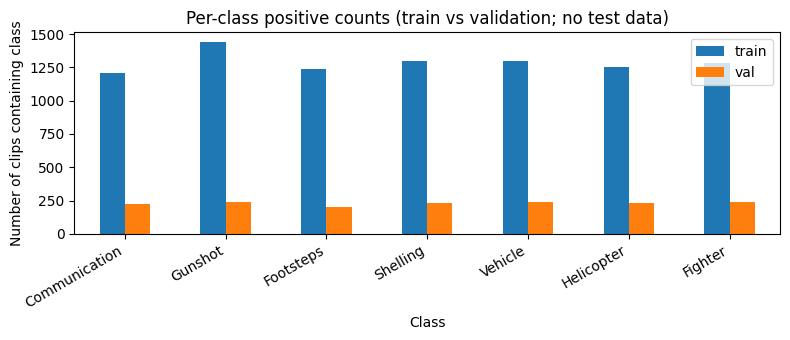

In [18]:
# D3. Label distribution plot (all axes labelled; training vs validation only).
fig, ax = plt.subplots(figsize=(8, 3.5))
cls_counts.plot.bar(ax=ax)
ax.set_xlabel("Class"); ax.set_ylabel("Number of clips containing class")
ax.set_title("Per-class positive counts (train vs validation; no test data)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## Section E — Preprocessing and DataLoaders

The prompt does not show an existing dataset class or preprocessing module, so this notebook uses a **small notebook-local adapter** that implements exactly the stated audio contract and nothing else:

- 16 kHz mono, exactly 160,000 samples (anything else raises — no silent padding/cropping);
- mel spectrogram: FFT 1024, hop 512, 128 mel bins, power 2.0, `log(mel + 1e-6)`;
- no augmentation, no normalisation beyond the log.

**Please check one thing against your project:** the log compression and epsilon (`LOG_EPS`) are my assumption of a typical convention, not something read from your code. If your project's preprocessing differs, replace `LogMel` with the project's function before training. The DataLoaders read only `train` and `val` rows, and the sets are built from separate dataframes.

In [19]:
# E1. Reproducibility helpers + the audio contract.
require_gates("environment", "config", "dataset")
SEED = int(EXP_CFG["seed"])
SR, SECONDS = int(DATA_CFG["sample_rate"]), int(DATA_CFG["duration_seconds"])
N_SAMPLES, N_FFT, HOP, N_MELS = SR * SECONDS, 1024, int(EXP_CFG["hop_length"]), 128
LOG_EPS = 1e-6
assert (SR, SECONDS, N_SAMPLES, HOP) == (16000, 10, 160000, 512)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def worker_init_fn(worker_id):
    s = (torch.initial_seed() + worker_id) % 2**32
    np.random.seed(s); random.seed(s)

set_seed(SEED)
print("seed set to", SEED)

seed set to 42


In [20]:
# E2. Dataset adapter (local, minimal, transparent) and DataLoaders.
class LogMel(nn.Module):
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, power=2.0)
    def forward(self, wav):                      # wav: (N,) -> (1, n_mels, frames)
        return torch.log(self.mel(wav) + LOG_EPS).unsqueeze(0)

class MadMixtureDataset(Dataset):
    def __init__(self, paths, targets):
        assert len(paths) == len(targets)
        self.paths, self.targets, self.logmel = list(paths), targets.astype(np.float32), LogMel()
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        wav, sr = sf.read(str(self.paths[i]), dtype="float32", always_2d=False)
        if wav.ndim > 1: wav = wav.mean(axis=1)
        if sr != SR or wav.shape[0] != N_SAMPLES:
            raise ValueError(f"{self.paths[i]}: sr={sr}, samples={wav.shape[0]}; expected {SR} Hz, {N_SAMPLES} samples")
        return self.logmel(torch.from_numpy(wav)), torch.from_numpy(self.targets[i])

def build_split(name):
    m = (META["_split"] == name).to_numpy()
    rel = META.loc[m, AUDIO_COL].tolist()
    paths = [resolve_audio(v) for v in rel]
    missing = [r for r, p in zip(rel, paths) if p is None]
    assert not missing, f"{len(missing)} {name} audio file(s) not found, e.g. {missing[:3]}"
    return MadMixtureDataset(paths, TARGETS_ALL[m]), paths

train_ds, train_paths = build_split("train")
val_ds, val_paths = build_split("val")
assert len(train_ds) == EXPECTED_TOTALS["train"] and len(val_ds) == EXPECTED_TOTALS["val"]
assert not (set(map(str, train_paths)) & set(map(str, val_paths))), "train/val share audio files"
SPLITS_USED = ["train", "val"]       # the official test set is never loaded in this notebook

def make_loader(ds, shuffle, seed_offset):
    g = torch.Generator(); g.manual_seed(SEED + seed_offset)
    nw = HP["num_workers"] if GATES["hyperparameters"] else 0
    return DataLoader(ds, batch_size=HP["batch_size"] if GATES["hyperparameters"] else 8, shuffle=shuffle,
                      num_workers=nw, worker_init_fn=worker_init_fn, generator=g,
                      pin_memory=(DEVICE.type == "cuda"), persistent_workers=(nw > 0), drop_last=False)

require_gates("hyperparameters")
train_loader = make_loader(train_ds, True, 0)
val_loader = make_loader(val_ds, False, 1)
print(f"train batches: {len(train_loader)} | val batches: {len(val_loader)} | batch_size={HP['batch_size']} | workers={HP['num_workers']}")

train batches: 171 | val batches: 31 | batch_size=32 | workers=0


input : (32, 1, 128, 313) torch.float32 | target: (32, 7) torch.float32
input range: [-13.82, 10.04] mean=-5.71
[gate:data_loaders] PASS shapes/dtypes/finiteness verified on a validation batch


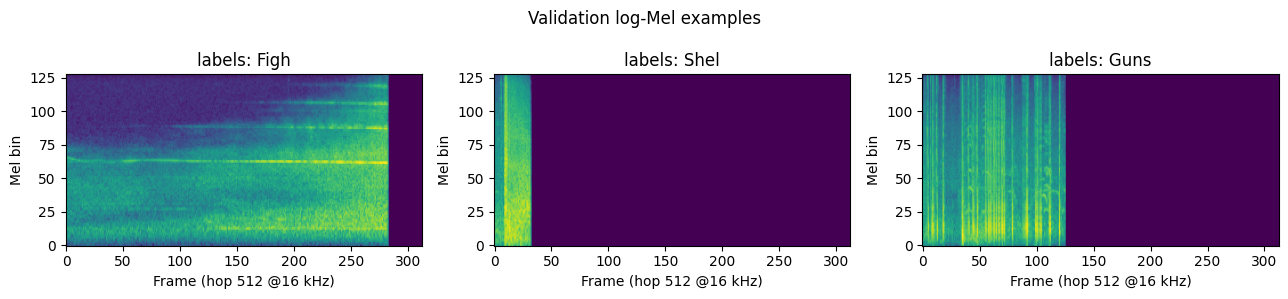

In [21]:
# E3. Verify real tensors: shape, dtype, finiteness (one validation batch; no training data consumed).
xb, yb = next(iter(val_loader))
print("input :", tuple(xb.shape), xb.dtype, "| target:", tuple(yb.shape), yb.dtype)
exp_frames = 1 + N_SAMPLES // HOP
assert xb.ndim == 4 and xb.shape[1:] == (1, N_MELS, exp_frames), f"unexpected input shape {tuple(xb.shape)}; expected (B,1,{N_MELS},{exp_frames})"
assert xb.dtype == torch.float32 and yb.dtype == torch.float32
assert yb.shape[1] == NUM_CLASSES and set(yb.unique().tolist()) <= {0.0, 1.0}
assert torch.isfinite(xb).all(), "non-finite values in log-mel input"
print(f"input range: [{xb.min():.2f}, {xb.max():.2f}] mean={xb.mean():.2f}")
set_gate("data_loaders", True, "shapes/dtypes/finiteness verified on a validation batch")

# representative spectrograms (validation split)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, k in zip(axes, range(3)):
    ax.imshow(xb[k, 0].numpy(), origin="lower", aspect="auto")
    ax.set_title("labels: " + ",".join(CLASS_NAMES[i][:4] for i in torch.nonzero(yb[k]).flatten().tolist()))
    ax.set_xlabel("Frame (hop 512 @16 kHz)"); ax.set_ylabel("Mel bin")
fig.suptitle("Validation log-Mel examples"); plt.tight_layout(); plt.show()

## Section F — Model construction and shape trace

The real `EnhancedALMEncoder` is imported and built with `use_fusion=False, use_class_queries=False`; all other arguments keep their class defaults. Shapes are **measured** with forward hooks on a real batch. The "expected" values below are only the theoretical derivation (313 frames → two (2,2) pools → 78; 128 mel → four /2 pools → 8) used as assertions; observed values are printed beside them.

In [22]:
# F1. Build B0 model and inspect it.
require_gates("environment", "data_loaders")
import inspect
set_seed(SEED)
MODEL_KWARGS = {"use_fusion": False, "use_class_queries": False}
model = EnhancedALMEncoder(**MODEL_KWARGS).to(DEVICE)
SIG_DEFAULTS = {k: v.default for k, v in inspect.signature(EnhancedALMEncoder.__init__).parameters.items()
                if v.default is not inspect.Parameter.empty}
print("effective constructor args:", {**SIG_DEFAULTS, **MODEL_KWARGS})
N_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters (measured): {N_PARAMS:,}")
assert not any(isinstance(m, nn.Sigmoid) for m in model.modules()), "model contains nn.Sigmoid; logits must be raw"
assert getattr(model, "class_query_head", None) is None, "class-query head is present although disabled"
fusion_modules = [n for n, _ in model.named_modules() if "fusion" in n.lower()]
assert not fusion_modules, f"fusion modules present although disabled: {fusion_modules}"
print("fusion modules: none | class_query_head: None")

effective constructor args: {'embed_dim': 256, 'num_classes': 7, 'num_heads': 8, 'num_layers': 6, 'ff_dim': 1024, 'dropout': 0.1, 'pooling': 'attention', 'use_fusion': False, 'use_class_queries': False, 'max_time_frames': 100}
trainable parameters (measured): 6,463,655
fusion modules: none | class_query_head: None


/home/sharad/Projects/ALM/ALM/utils/enhanced_alm_mad_encoder.py:220: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


In [23]:
# F2. Shape tracing with temporary forward hooks (removed afterwards). Eval mode, no grad.
shapes, hooks = {}, []
def grab(name, use_input=False):
    def h(mod, inp, out):
        t = inp[0] if use_input else out
        shapes[name] = tuple(t.shape)
    return h
for attr, name, use_in in [("backbone", "cnn_backbone_out", False),
                           ("patch_proj", "tokens_before_projection", True),
                           ("transformer", "transformer_out", False)]:
    assert hasattr(model, attr), f"model has no attribute {attr!r}; the trace hooks need updating to the real module names"
    hooks.append(getattr(model, attr).register_forward_hook(grab(name, use_in)))

model.eval()
with torch.no_grad():
    probe = xb[:2].to(DEVICE)
    logits = model(probe)
for h in hooks: h.remove()
shapes = {"input_logmel": tuple(probe.shape), **shapes, "logits": tuple(logits.shape)}

B, T_in = probe.shape[0], probe.shape[-1]
theory = {"cnn_backbone_out": (B, 256, 8, T_in // 2 // 2),
          "tokens_before_projection": (B, T_in // 4, 256 * 8),
          "transformer_out": (B, T_in // 4, 256), "logits": (B, NUM_CLASSES)}
print(f"{'stage':28s} {'observed':22s} theoretical")
for k, v in shapes.items():
    print(f"{k:28s} {str(v):22s} {theory.get(k, '-')}")
mismatch = {k: (shapes[k], v) for k, v in theory.items() if shapes[k] != v}
assert not mismatch, f"shape mismatch (observed, theoretical): {mismatch}. Not modifying the model; inspect the architecture."

seq_len = shapes["tokens_before_projection"][1]
pos_cap = model.pos_embed.shape[1]
print(f"token sequence length={seq_len} | positional-embedding capacity={pos_cap}")
assert seq_len <= pos_cap, f"sequence length {seq_len} exceeds positional capacity {pos_cap}"
assert logits.shape == (B, NUM_CLASSES) and torch.isfinite(logits).all()
print("logit range (raw, un-squashed): [%.3f, %.3f]" % (logits.min(), logits.max()))
set_gate("model", True, f"B0 model verified; {N_PARAMS:,} trainable parameters")

stage                        observed               theoretical
input_logmel                 (2, 1, 128, 313)       -
cnn_backbone_out             (2, 256, 8, 78)        (2, 256, 8, 78)
tokens_before_projection     (2, 78, 2048)          (2, 78, 2048)
transformer_out              (2, 78, 256)           (2, 78, 256)
logits                       (2, 7)                 (2, 7)
token sequence length=78 | positional-embedding capacity=100
logit range (raw, un-squashed): [-0.552, 0.554]
[gate:model] PASS B0 model verified; 6,463,655 trainable parameters


## Section G — Loss, optimizer, and scheduler

**Positive class weights (training labels only).** For class *c*, with `pos_c` positive and `neg_c` negative training clips:

`pos_weight_c = clip(neg_c / pos_c, max = 8.0)`

Edge cases (each reported by the next cell and logged):
- `pos_c == 0` → the ratio is undefined; weight is set to **1.0** (neutral) and a warning is raised.
- `neg_c == 0` → ratio is 0; weight is set to **1.0** (neutral) with a warning.

Validation labels never enter this calculation. The optimizer is AdamW; the schedule is `CosineAnnealingLR` stepped **once per epoch after that epoch's optimizer steps**, with `T_max = max_epochs`. No warm-up or gradient clipping is added because none is specified.

In [24]:
# G1. pos_weight from training targets only, loss, optimizer, scheduler.
require_gates("hyperparameters", "data_loaders", "model")
y_train = train_ds.targets                                   # (N_train, 7) training labels only
pos = y_train.sum(0); neg = y_train.shape[0] - pos
POS_WEIGHT_WARNINGS, pw = [], np.ones(NUM_CLASSES, dtype=np.float32)
for c, name in enumerate(CLASS_NAMES):
    if pos[c] == 0 or neg[c] == 0:
        POS_WEIGHT_WARNINGS.append(f"{name}: pos={int(pos[c])}, neg={int(neg[c])} -> weight set to 1.0")
    else:
        pw[c] = min(neg[c] / pos[c], HP["pos_weight_cap"])
for w in POS_WEIGHT_WARNINGS: print("WARNING:", w)
POS_WEIGHT = torch.tensor(pw, dtype=torch.float32, device=DEVICE)
print(pd.DataFrame({"pos": pos.astype(int), "neg": neg.astype(int),
                    "raw_neg/pos": np.where(pos > 0, neg / np.maximum(pos, 1), np.nan),
                    "pos_weight": pw}, index=CLASS_NAMES).round(3))

criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
optimizer = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HP["max_epochs"], eta_min=HP["eta_min"])
print("\neffective hyperparameters:", json.dumps({k: HP[k] for k in HP}, indent=1))
print("hyperparameter sources   :", json.dumps(HP_SOURCE, indent=1))
print("optimizer: AdamW | scheduler: CosineAnnealingLR(T_max=%d, eta_min=%g), stepped per epoch" % (HP["max_epochs"], HP["eta_min"]))

                pos   neg  raw_neg/pos  pos_weight
Communication  1207  4257        3.527       3.527
Gunshot        1441  4023        2.792       2.792
Footsteps      1238  4226        3.414       3.414
Shelling       1297  4167        3.213       3.213
Vehicle        1295  4169        3.219       3.219
Helicopter     1252  4212        3.364       3.364
Fighter        1286  4178        3.249       3.249

effective hyperparameters: {
 "batch_size": 32,
 "lr": 0.0003,
 "weight_decay": 0.01,
 "max_epochs": 60,
 "pos_weight_cap": 8.0,
 "eta_min": 0.0,
 "num_workers": 0
}
hyperparameter sources   : {
 "batch_size": "user override in notebook",
 "lr": "user override in notebook",
 "weight_decay": "user override in notebook",
 "max_epochs": "B0 task statement (maximum 60 epochs); not in config",
 "pos_weight_cap": "experiment config 'loss' string (capped at 8.0)",
 "eta_min": "PyTorch CosineAnnealingLR default (NOT from project) - confirm",
 "num_workers": "notebook default (NOT from project

## Section K — Run directory and persistent logging *(placed before training because the loop needs it)*

Creates `runs/<run_id>/` with `mkdir(exist_ok=False)`: if the run already exists, the cell **stops** instead of overwriting anything. To start a fresh experiment, change `run_id` in the experiment config deliberately (e.g. add a suffix) — do not delete old runs.

Logging uses the standard `logging` module:
- one logger, `b0`, whose handlers are **cleared before being re-added**, so re-running the cell never duplicates output;
- a **file handler** (`training.log`, DEBUG, flushed on every record) and a **console handler** that writes through `tqdm.write` so progress bars are not broken (INFO);
- format `YYYY-MM-DD HH:MM:SS | LEVEL | message`.

Re-running this cell in the same kernel after it has succeeded is safe: it reuses the run directory created by *this* kernel session, and never touches a directory it did not create.

In [26]:
# K1. Create run directory (never overwrite) and configure logger without duplicate handlers.
require_gates("environment", "config", "hyperparameters", "dataset", "data_loaders", "model")
RUN_ID = EXP_CFG["run_id"]
RUN_DIR = ROOT / "runs" / RUN_ID
PLOTS_DIR = RUN_DIR / "plots"
if globals().get("_RUN_DIR_CREATED_BY_THIS_KERNEL") == str(RUN_DIR):
    print("Reusing run directory created earlier in this kernel session:", RUN_DIR)
else:
    if RUN_DIR.exists():
        raise FileExistsError(
            f"Run directory already exists: {RUN_DIR}. Refusing to overwrite logs/metrics/checkpoints. "
            "Choose a new run_id in configs/experiments/B0_source_disjoint_v1.json (explicitly approved) and re-run.")
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    PLOTS_DIR.mkdir(exist_ok=False)
    _RUN_DIR_CREATED_BY_THIS_KERNEL = str(RUN_DIR)

class TqdmConsoleHandler(logging.Handler):
    def emit(self, record):
        try: tqdm.write(self.format(record))
        except Exception: self.handleError(record)

FMT = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%Y-%m-%d %H:%M:%S")
logger = logging.getLogger("b0")
logger.setLevel(logging.DEBUG); logger.propagate = False
for h in list(logger.handlers):
    h.close(); logger.removeHandler(h)
fh = logging.FileHandler(RUN_DIR / "training.log", mode="a", encoding="utf-8"); fh.setLevel(logging.DEBUG); fh.setFormatter(FMT)
ch = TqdmConsoleHandler(); ch.setLevel(logging.INFO); ch.setFormatter(FMT)
logger.addHandler(fh); logger.addHandler(ch)
assert len(logger.handlers) == 2

def git_commit():
    try: return subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], capture_output=True, text=True, timeout=10).stdout.strip() or None
    except Exception: return None

EFFECTIVE_CONFIG = {
    "run_id": RUN_ID, "created": dt.datetime.now().isoformat(timespec="seconds"), "git_commit": git_commit(),
    "data_config": DATA_CFG, "experiment_config": EXP_CFG, "hyperparameters": HP, "hyperparameter_sources": HP_SOURCE,
    "model_class": "EnhancedALMEncoder", "model_kwargs": MODEL_KWARGS, "model_defaults": SIG_DEFAULTS,
    "trainable_parameters": N_PARAMS, "class_names": list(CLASS_NAMES),
    "pos_weight": pw.tolist(), "pos_weight_warnings": POS_WEIGHT_WARNINGS,
    "audio": {"sr": SR, "seconds": SECONDS, "n_fft": N_FFT, "hop": HOP, "n_mels": N_MELS, "log_eps": LOG_EPS},
    "seed": SEED, "device": str(DEVICE), "library_versions": versions, "splits_used": SPLITS_USED,
    "official_test_used": False, "checkpoint_selection": "best validation mAP",
    "loss": "BCEWithLogitsLoss(pos_weight capped at 8.0, training labels only)",
    "optimizer": "AdamW", "scheduler": "CosineAnnealingLR stepped per epoch",
}
cfg_path = RUN_DIR / "config.json"
if not cfg_path.exists():
    with open(cfg_path, "x") as f: json.dump(EFFECTIVE_CONFIG, f, indent=2, default=str)
logger.info("Experiment startup | run_id=%s | dir=%s", RUN_ID, RUN_DIR)
logger.info("Dataset version=%s | audit passed | train=%d val=%d | limitations: parent-video identity unknown for 150 official-test clips; no audio-fingerprint dedup",
            DATA_CFG["dataset_version"], len(train_ds), len(val_ds))
logger.info("Env | python=%s torch=%s numpy=%s soundfile=%s | device=%s | seed=%d",
            versions["python"], versions["torch"], versions["numpy"], versions["soundfile"], DEVICE, SEED)
logger.info("Model flags | %s | trainable_params=%d", MODEL_KWARGS, N_PARAMS)
logger.info("Hyperparameters | %s | sources=%s", HP, HP_SOURCE)
logger.info("DataLoaders | batch_size=%d workers=%d train_batches=%d val_batches=%d", HP["batch_size"], HP["num_workers"], len(train_loader), len(val_loader))
logger.info("pos_weight=%s", np.round(pw, 3).tolist())
for w in POS_WEIGHT_WARNINGS: logger.warning("pos_weight: %s", w)
for k, v in HP_SOURCE.items():
    if "NOT from project" in v: logger.warning("Hyperparameter %s=%s uses a non-project default (%s)", k, HP[k], v)
print("\nLog file:", RUN_DIR / "training.log")

2026-10-11 00:25:42 | INFO | Experiment startup | run_id=B0_mad_source_disjoint_v1_seed42 | dir=/home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42
2026-10-11 00:25:42 | INFO | Dataset version=mad_source_disjoint_v1 | audit passed | train=5464 val=965 | limitations: parent-video identity unknown for 150 official-test clips; no audio-fingerprint dedup
2026-10-11 00:25:42 | INFO | Env | python=3.12.3 torch=2.14.1+cu132 numpy=2.2.6 soundfile=0.13.1 | device=cuda | seed=42
2026-10-11 00:25:42 | INFO | Model flags | {'use_fusion': False, 'use_class_queries': False} | trainable_params=6463655
2026-10-11 00:25:42 | INFO | Hyperparameters | {'batch_size': 32, 'lr': 0.0003, 'weight_decay': 0.01, 'max_epochs': 60, 'pos_weight_cap': 8.0, 'eta_min': 0.0, 'num_workers': 0} | sources={'batch_size': 'user override in notebook', 'lr': 'user override in notebook', 'weight_decay': 'user override in notebook', 'max_epochs': 'B0 task statement (maximum 60 epochs); not in config', 'pos_weig

## Sections H, I, J — Training loop with `tqdm` monitoring

What the loop does each epoch:
1. `model.train()`; for each training batch: `zero_grad` → forward (raw logits) → `BCEWithLogitsLoss` → `backward` → `AdamW.step()`. A non-finite loss raises immediately (no silently skipped batches).
2. `scheduler.step()` once, **after** the epoch's optimizer steps. The logged learning rate is the one that was used *during* that epoch.
3. `model.eval()` + `torch.no_grad()`; collect validation logits → sigmoid probabilities. **Validation mAP** = mean over classes of `average_precision_score(y_true_c, prob_c)`. Classes with no positive validation examples are skipped (logged as a warning) rather than counted as 0.
4. If validation mAP improved, `best_model.pt` is written atomically (temp file → `os.replace`).
5. One row is appended to `metrics.csv`, `history.json` is rewritten atomically, and a summary line is logged.

**Progress bars.** Two `tqdm.auto` bars per epoch (training, validation) with `leave=False`, so finished bars disappear and the notebook does not fill with lines. The training bar shows `Epoch e/60 [train]`, batch progress, running mean loss and current LR; the validation bar shows running loss. mAP is shown once per epoch because it is only meaningful over the whole validation set. Bars refresh at most every 0.5 s.

Resume is **not implemented**: an interrupted run keeps its logs, metrics, history and best checkpoint, but must be restarted under a new `run_id`. This avoids silently mixing incompatible experiments.

In [27]:
# I1. Training/validation functions and artifact writers (definitions only; nothing runs yet).
def atomic_write_bytes(path, writer):
    path = Path(path); tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "wb") as f:
        writer(f); f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)

def atomic_json(path, obj):
    atomic_write_bytes(path, lambda f: f.write(json.dumps(obj, indent=2, default=str).encode()))

def save_best(epoch, val_map, per_class_ap):
    payload = {"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
               "scheduler_state_dict": scheduler.state_dict(), "epoch": int(epoch), "val_map": float(val_map),
               "per_class_val_ap": {k: (None if v != v else float(v)) for k, v in per_class_ap.items()},
               "model_class": "EnhancedALMEncoder", "model_kwargs": dict(MODEL_KWARGS), "class_names": list(CLASS_NAMES),
               "run_id": RUN_ID, "seed": SEED, "git_commit": EFFECTIVE_CONFIG["git_commit"],
               "hyperparameters": dict(HP), "pos_weight": pw.tolist(), "splits_used": list(SPLITS_USED),
               "selection_metric": "validation mAP", "official_test_used": False}
    atomic_write_bytes(RUN_DIR / "best_model.pt", lambda f: torch.save(payload, f))

METRIC_FIELDS = (["epoch", "train_loss", "val_loss", "val_map", "learning_rate", "epoch_seconds", "is_best", "best_val_map_so_far"]
                 + [f"val_ap_{c}" for c in CLASS_NAMES])
def append_metrics_row(row):
    p = RUN_DIR / "metrics.csv"; new = not p.exists()
    with open(p, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=METRIC_FIELDS)
        if new: w.writeheader()
        w.writerow({k: row.get(k) for k in METRIC_FIELDS}); f.flush(); os.fsync(f.fileno())

def train_one_epoch(epoch, total):
    model.train(); torch.set_grad_enabled(True)
    lr = optimizer.param_groups[0]["lr"]; run_sum, seen = 0.0, 0
    bar = tqdm(train_loader, desc=f"Epoch {epoch}/{total} [train]", leave=False, dynamic_ncols=True, mininterval=0.5)
    for x, y in bar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        if logits.shape != (x.shape[0], NUM_CLASSES): raise RuntimeError(f"bad logits shape {tuple(logits.shape)}")
        loss = criterion(logits, y)
        if not torch.isfinite(loss): raise FloatingPointError(f"non-finite training loss at epoch {epoch}: {loss.item()}")
        loss.backward(); optimizer.step()
        run_sum += loss.item() * x.shape[0]; seen += x.shape[0]
        bar.set_postfix_str(f"loss={run_sum/seen:.4f} lr={lr:.2e}", refresh=False)
    bar.close()
    return run_sum / seen, lr

@torch.no_grad()
def validate(epoch, total):
    model.eval()
    run_sum, seen, probs, targs = 0.0, 0, [], []
    bar = tqdm(val_loader, desc=f"Epoch {epoch}/{total} [val]", leave=False, dynamic_ncols=True, mininterval=0.5)
    for x, y in bar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x); loss = criterion(logits, y)
        if not torch.isfinite(loss): raise FloatingPointError(f"non-finite validation loss at epoch {epoch}")
        run_sum += loss.item() * x.shape[0]; seen += x.shape[0]
        probs.append(torch.sigmoid(logits).cpu().numpy()); targs.append(y.cpu().numpy())
        bar.set_postfix_str(f"loss={run_sum/seen:.4f}", refresh=False)
    bar.close()
    P, Y = np.concatenate(probs), np.concatenate(targs)
    aps = {}
    for c, name in enumerate(CLASS_NAMES):
        if Y[:, c].sum() == 0:
            aps[name] = float("nan"); logger.warning("Epoch %d: no positive validation examples for %s; excluded from mAP", epoch, name)
        else:
            aps[name] = float(average_precision_score(Y[:, c], P[:, c]))
    vals = [v for v in aps.values() if v == v]
    if not vals: raise RuntimeError("validation mAP undefined: no class has positive examples")
    return run_sum / seen, float(np.mean(vals)), aps
print("training functions defined")

training functions defined


In [28]:
# I2. Main loop definition (defined here, started in the next cell).
def run_training():
    require_gates("environment", "config", "hyperparameters", "dataset", "data_loaders", "model")
    assert len(logger.handlers) == 2, "logger not initialised; run the Section K cell first"
    assert not (RUN_DIR / "metrics.csv").exists() and not (RUN_DIR / "best_model.pt").exists(), \
        "This run already has metrics/checkpoint. Not overwriting; use a new run_id."
    total = HP["max_epochs"]; history, best_map, best_epoch = [], -float("inf"), None
    t_start = time.time()
    logger.info("TRAINING START | epochs=%d | device=%s", total, DEVICE)
    try:
        for epoch in range(1, total + 1):
            t0 = time.time(); logger.debug("Epoch %d/%d start", epoch, total)
            train_loss, lr = train_one_epoch(epoch, total)
            val_loss, val_map, aps = validate(epoch, total)
            scheduler.step()                                  # after the epoch's optimizer steps
            is_best = val_map > best_map
            if is_best:
                best_map, best_epoch = val_map, epoch
                save_best(epoch, val_map, aps)
                logger.info("Best checkpoint updated | epoch=%d | val_mAP=%.4f | %s", epoch, val_map, RUN_DIR / "best_model.pt")
            secs = time.time() - t0
            row = {"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_map": val_map, "learning_rate": lr,
                   "epoch_seconds": secs, "is_best": int(is_best), "best_val_map_so_far": best_map,
                   **{f"val_ap_{k}": v for k, v in aps.items()}}
            append_metrics_row(row); history.append(row)
            atomic_json(RUN_DIR / "history.json", {"run_id": RUN_ID, "completed_epochs": epoch, "best_epoch": best_epoch,
                                                   "best_val_map": best_map, "epochs": history})
            logger.info("Epoch %d/%d | train_loss=%.4f | val_loss=%.4f | val_mAP=%.4f | lr=%.3e | time=%.1fs | best_updated=%s",
                        epoch, total, train_loss, val_loss, val_map, lr, secs, is_best)
        logger.info("TRAINING COMPLETE | epochs=%d | best_epoch=%s | best_val_mAP=%.4f | total_time=%.1fs",
                    total, best_epoch, best_map, time.time() - t_start)
    except KeyboardInterrupt:
        logger.warning("INTERRUPTED by user at epoch %d; artifacts written so far are preserved. Resume is not supported; start a new run_id.", len(history) + 1)
        raise
    except Exception:
        logger.exception("TRAINING FAILED (critical) - traceback follows")
        raise
    finally:
        for h in logger.handlers: h.flush()
    return history
print("run_training() defined; it has NOT been started.")

run_training() defined; it has NOT been started.


In [29]:
# START TRAINING  <-- running this cell begins the 60-epoch B0 experiment. Official test data are not used.
HISTORY = run_training()

2026-10-11 00:25:49 | INFO | TRAINING START | epochs=60 | device=cuda


2026-10-11 00:26:57 | INFO | Best checkpoint updated | epoch=1 | val_mAP=0.6853 | /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42/best_model.pt
2026-10-11 00:26:57 | INFO | Epoch 1/60 | train_loss=0.8667 | val_loss=0.7504 | val_mAP=0.6853 | lr=3.000e-04 | time=68.2s | best_updated=True


2026-10-11 00:28:06 | INFO | Best checkpoint updated | epoch=2 | val_mAP=0.7893 | /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42/best_model.pt
2026-10-11 00:28:06 | INFO | Epoch 2/60 | train_loss=0.7153 | val_loss=0.6380 | val_mAP=0.7893 | lr=2.998e-04 | time=68.9s | best_updated=True


2026-10-11 00:29:16 | INFO | Best checkpoint updated | epoch=3 | val_mAP=0.7966 | /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42/best_model.pt
2026-10-11 00:29:16 | INFO | Epoch 3/60 | train_loss=0.6430 | val_loss=0.6148 | val_mAP=0.7966 | lr=2.992e-04 | time=70.0s | best_updated=True


2026-10-11 00:30:25 | INFO | Best checkpoint updated | epoch=4 | val_mAP=0.8149 | /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42/best_model.pt
2026-10-11 00:30:25 | INFO | Epoch 4/60 | train_loss=0.5899 | val_loss=0.6035 | val_mAP=0.8149 | lr=2.982e-04 | time=69.2s | best_updated=True


...

2026-10-11 01:28:22 | INFO | Epoch 56/60 | train_loss=0.0116 | val_loss=1.2402 | val_mAP=0.8254 | lr=5.111e-06 | time=68.1s | best_updated=False


2026-10-11 01:29:29 | INFO | Epoch 57/60 | train_loss=0.0107 | val_loss=1.2317 | val_mAP=0.8253 | lr=3.278e-06 | time=67.9s | best_updated=False


2026-10-11 01:30:38 | INFO | Epoch 58/60 | train_loss=0.0105 | val_loss=1.2353 | val_mAP=0.8257 | lr=1.847e-06 | time=68.1s | best_updated=False


2026-10-11 01:31:46 | INFO | Epoch 59/60 | train_loss=0.0114 | val_loss=1.2420 | val_mAP=0.8255 | lr=8.217e-07 | time=68.0s | best_updated=False


2026-10-11 01:32:54 | INFO | Epoch 60/60 | train_loss=0.0115 | val_loss=1.2372 | val_mAP=0.8257 | lr=2.056e-07 | time=68.2s | best_updated=False
2026-10-11 01:32:54 | INFO | TRAINING COMPLETE | epochs=60 | best_epoch=9 | best_val_mAP=0.8534 | total_time=4025.2s


## Section L — Results and visualization

Run after training finishes (or after an interruption — it reads whatever `metrics.csv` already contains). All figures here are **validation** metrics; there are no test metrics. Plot filenames start with `val_` / `loss_` accordingly.

completed epochs : 60
best epoch       : 9
best validation mAP: 0.8534
checkpoint       : /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42/best_model.pt
run directory    : /home/sharad/Projects/ALM/ALM/runs/B0_mad_source_disjoint_v1_seed42


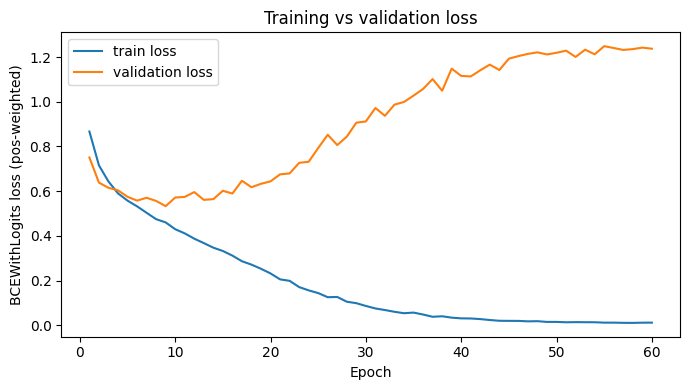

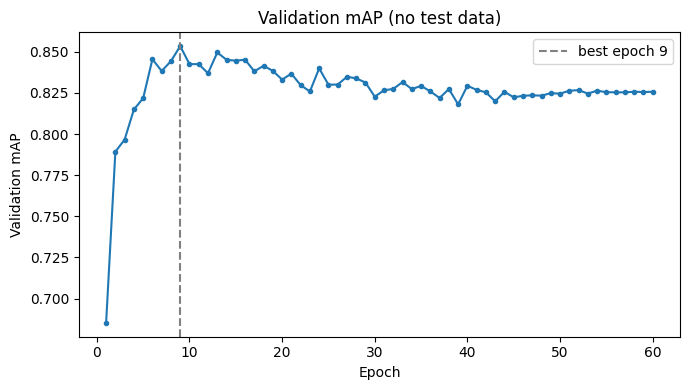

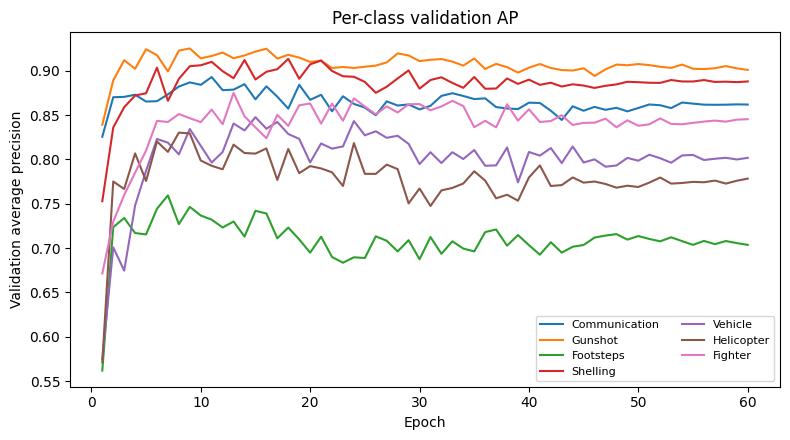

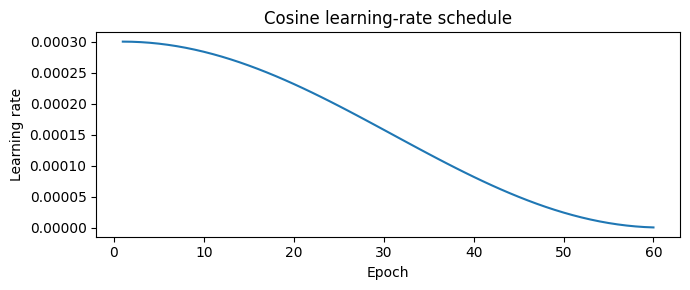

In [30]:
# L1. Load metrics and plot (saved into runs/<run_id>/plots/).
M = pd.read_csv(RUN_DIR / "metrics.csv")
assert len(M) > 0, "metrics.csv has no rows yet"
best = M.loc[M["val_map"].idxmax()]
print(f"completed epochs : {len(M)}")
print(f"best epoch       : {int(best['epoch'])}")
print(f"best validation mAP: {best['val_map']:.4f}")
print(f"checkpoint       : {RUN_DIR / 'best_model.pt'}")
print(f"run directory    : {RUN_DIR}")
if len(M) < HP["max_epochs"]: print(f"WARNING: run incomplete ({len(M)}/{HP['max_epochs']} epochs).")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(M["epoch"], M["train_loss"], label="train loss"); ax.plot(M["epoch"], M["val_loss"], label="validation loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("BCEWithLogits loss (pos-weighted)"); ax.set_title("Training vs validation loss"); ax.legend()
fig.tight_layout(); fig.savefig(PLOTS_DIR / "loss_train_vs_val.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(M["epoch"], M["val_map"], marker="o", ms=3); ax.axvline(best["epoch"], ls="--", c="gray", label=f"best epoch {int(best['epoch'])}")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation mAP"); ax.set_title("Validation mAP (no test data)"); ax.legend()
fig.tight_layout(); fig.savefig(PLOTS_DIR / "val_map.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in CLASS_NAMES: ax.plot(M["epoch"], M[f"val_ap_{c}"], label=c)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation average precision"); ax.set_title("Per-class validation AP"); ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(PLOTS_DIR / "val_per_class_ap.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(M["epoch"], M["learning_rate"])
ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate"); ax.set_title("Cosine learning-rate schedule")
fig.tight_layout(); fig.savefig(PLOTS_DIR / "learning_rate.png", dpi=150); plt.show()

## Section M — Final integrity checks

Reloads the saved best checkpoint, rebuilds the model from the *saved* constructor arguments, and checks that logs, metrics, history and config belong to the same run. These checks only mean something **after you have executed them**; the notebook does not pre-fill any result.

In [31]:
# M1. Checkpoint reload and consistency checks (validation data only).
ckpt_path = RUN_DIR / "best_model.pt"
assert ckpt_path.is_file(), f"checkpoint missing: {ckpt_path}"
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
checks = {}
checks["checkpoint loads"] = True
checks["run_id matches"] = ck["run_id"] == RUN_ID == EXP_CFG["run_id"]
checks["model_kwargs are B0"] = ck["model_kwargs"] == {"use_fusion": False, "use_class_queries": False}
checks["seed matches"] = ck["seed"] == EXP_CFG["seed"] == 42
checks["official test not used"] = (ck["official_test_used"] is False) and ck["splits_used"] == ["train", "val"]

reloaded = EnhancedALMEncoder(**ck["model_kwargs"]); reloaded.load_state_dict(ck["model_state_dict"]); reloaded.to(DEVICE).eval()
checks["no fusion modules"] = not [n for n, _ in reloaded.named_modules() if "fusion" in n.lower()]
checks["class_query_head is None"] = getattr(reloaded, "class_query_head", None) is None
with torch.no_grad():
    out = reloaded(xb[:4].to(DEVICE))
checks["seven logits per example"] = tuple(out.shape) == (4, NUM_CLASSES)
checks["logits finite"] = bool(torch.isfinite(out).all())

M = pd.read_csv(RUN_DIR / "metrics.csv")
H = json.loads((RUN_DIR / "history.json").read_text())
CFG_SAVED = json.loads((RUN_DIR / "config.json").read_text())
checks["metrics rows == history epochs"] = len(M) == H["completed_epochs"] == len(H["epochs"])
checks["checkpoint epoch == best metrics epoch"] = int(ck["epoch"]) == int(M.loc[M["val_map"].idxmax(), "epoch"]) == H["best_epoch"]
checks["checkpoint val_mAP == best metrics val_mAP"] = abs(ck["val_map"] - M["val_map"].max()) < 1e-9
checks["config.json run_id matches"] = CFG_SAVED["run_id"] == RUN_ID and CFG_SAVED["official_test_used"] is False
log_text = (RUN_DIR / "training.log").read_text()
checks["training.log names this run"] = RUN_ID in log_text and "TRAINING START" in log_text
checks["training.log has completion record"] = "TRAINING COMPLETE" in log_text
checks["no duplicate logger handlers"] = len(logging.getLogger("b0").handlers) == 2

for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
failed = [k for k, v in checks.items() if not v]
if failed:
    logger.error("Final integrity checks FAILED: %s", failed); raise AssertionError(f"Integrity checks failed: {failed}")
logger.info("Final integrity checks passed (%d checks).", len(checks))
print("\nAll final integrity checks passed. Artifacts:")
for p in sorted(RUN_DIR.rglob("*")):
    if p.is_file(): print("  ", p.relative_to(ROOT), f"({p.stat().st_size:,} bytes)")

PASS checkpoint loads
PASS run_id matches
PASS model_kwargs are B0
PASS seed matches
PASS official test not used
PASS no fusion modules
PASS class_query_head is None
PASS seven logits per example
PASS logits finite
PASS metrics rows == history epochs
PASS checkpoint epoch == best metrics epoch
PASS checkpoint val_mAP == best metrics val_mAP
PASS config.json run_id matches
PASS training.log names this run
PASS training.log has completion record
PASS no duplicate logger handlers
2026-10-11 01:32:55 | INFO | Final integrity checks passed (16 checks).

All final integrity checks passed. Artifacts:
   runs/B0_mad_source_disjoint_v1_seed42/best_model.pt (77,704,983 bytes)
   runs/B0_mad_source_disjoint_v1_seed42/config.json (3,756 bytes)
   runs/B0_mad_source_disjoint_v1_seed42/history.json (37,485 bytes)
   runs/B0_mad_source_disjoint_v1_seed42/metrics.csv (15,462 bytes)
   runs/B0_mad_source_disjoint_v1_seed42/plots/learning_rate.png (42,839 bytes)
   runs/B0_mad_source_disjoint_v1_seed42/

/home/sharad/Projects/ALM/ALM/utils/enhanced_alm_mad_encoder.py:220: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


### Notes for the audit
- The official test set was not loaded or evaluated by any cell in this notebook. Evaluating it is a separate, deliberate step to take only after B0 is frozen.
- `"TRAINING COMPLETE"` in `training.log` only appears if all epochs ran; an interrupted run will (correctly) fail the completion check in M1 — interpret that as "incomplete", not as a bug.
- Unconfirmed assumptions to review: log-Mel compression (`log(mel+1e-6)`), `eta_min` and `num_workers` defaults if not in the config, and the metadata/manifest file discovery.